# Notebook 04 — Novel Models (TabNet & TabTransformer)
### DSA 3900 | Maternal Health Risk Prediction — Real KDHS 2022 Data

Trains two deep learning models designed specifically for tabular data:

1. **TabNet** (Arik & Pfister, 2021) — attention-based sequential feature
   selection; learns which features to use at each decision step.
   Native interpretability via attention weights (no SHAP needed).

2. **TabTransformer** (Huang et al., 2020) — applies Transformer
   self-attention to categorical embeddings, then concatenates with
   continuous features for final MLP classification.

Both are state-of-the-art deep learning approaches for structured/tabular
data, justified as novel contributions in the DSA 3900 project scope.

**Input:** `01_Data/processed/` — X_train, X_val, X_test, y_train, y_val  
**Output:** `03_Models_Saved/` — tabnet_model.zip, tabtransformer_best.pt  
           `04_Outputs/results/` — all_results_so_far.csv (updated)

In [3]:
# ── Standard libraries ────────────────────────────────────────────────────────
import pandas as pd
import numpy as np
import torch
import joblib
import optuna
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from pytorch_tabnet.tab_model import TabNetClassifier
from sklearn.metrics import (accuracy_score, f1_score, roc_auc_score,
                             classification_report, confusion_matrix)

# ── Suppress Optuna logs for cleaner output ───────────────────────────────────
optuna.logging.set_verbosity(optuna.logging.WARNING)

# ── Device: use GPU if available, otherwise CPU ───────────────────────────────
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

# ── Project paths ─────────────────────────────────────────────────────────────
PROC = Path('../../01_Data/processed')
MOUT = Path('../../03_Models_Saved')
FOUT = Path('../../04_Outputs/figures')
ROUT = Path('../../04_Outputs/results')

print(f'Device : {DEVICE}')
print(f'PyTorch: {torch.__version__}')
print(f'Optuna : {optuna.__version__}')

Device : cpu
PyTorch: 2.14.1+cpu
Optuna : 5.0.0


## 1. Load Splits
Load the preprocessed train, validation and test splits saved by Notebook 01.
TabNet requires numpy float32 arrays rather than DataFrames.

In [4]:
# Load preprocessed splits from disk
# TabNet requires numpy float32 arrays — convert immediately after loading
X_train = pd.read_csv(PROC / 'X_train.csv').values.astype(np.float32)
X_val   = pd.read_csv(PROC / 'X_val.csv').values.astype(np.float32)
X_test  = pd.read_csv(PROC / 'X_test.csv').values.astype(np.float32)

# Load target vectors as 1-D numpy integer arrays
y_train = pd.read_csv(PROC / 'y_train.csv').squeeze().values
y_val   = pd.read_csv(PROC / 'y_val.csv').squeeze().values
y_test  = pd.read_csv(PROC / 'y_test.csv').squeeze().values

CLASS_NAMES = ['Low', 'Moderate', 'High']
N_FEATURES  = X_train.shape[1]

print(f'Splits loaded ✓ | Train {X_train.shape} | Val {X_val.shape} | Test {X_test.shape}')

Splits loaded ✓ | Train (9054, 13) | Val (1559, 13) | Test (1559, 13)


## 2. Evaluation Helper
Reusable function that computes accuracy, macro F1, High-Risk F1 and ROC-AUC,
prints a classification report and saves a confusion matrix PNG.

In [5]:
def evaluate_model(model, X, y, model_name, split='Val'):
    """Compute metrics, print classification report, save confusion matrix."""
    y_pred  = model.predict(X)
    y_proba = model.predict_proba(X)

    acc   = accuracy_score(y, y_pred)
    macro = f1_score(y, y_pred, average='macro')
    high  = f1_score(y, y_pred, average=None)[2]
    auc   = roc_auc_score(y, y_proba, multi_class='ovr', average='macro')

    print(f'\n=== {model_name} ({split}) ===')
    print(classification_report(y, y_pred, target_names=CLASS_NAMES))

    # ── Confusion matrix ──────────────────────────────────────────────────────
    cm = confusion_matrix(y, y_pred)
    fig, ax = plt.subplots(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax)
    ax.set_title(f'{model_name} — {split} Confusion Matrix')
    ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
    plt.tight_layout()
    fname = f'{model_name.replace(" ", "_")}_{split}_cm.png'
    fig.savefig(FOUT / fname, dpi=150)
    plt.show()

    return {'model': model_name, 'accuracy': round(acc, 4),
            'macro_f1': round(macro, 4), 'high_risk_f1': round(high, 4),
            'roc_auc': round(auc, 4)}

print('evaluate_model() ready ✓')

evaluate_model() ready ✓


## 3. TabNet — Optuna Hyperparameter Optimisation
TabNet is an attention-based neural network designed specifically for tabular data.
It uses sequential attention to select relevant features at each decision step,
providing both high performance and built-in interpretability via feature importance masks.
Optuna TPE sampler runs 20 trials maximising High-Risk F1 on the validation set.

In [6]:
def tabnet_objective(trial):
    """Optuna objective — maximise High-Risk F1 on validation set."""
    params = {
        'n_d':          trial.suggest_int('n_d', 8, 64),        # width of decision step
        'n_a':          trial.suggest_int('n_a', 8, 64),        # width of attention step
        'n_steps':      trial.suggest_int('n_steps', 3, 10),    # number of decision steps
        'gamma':        trial.suggest_float('gamma', 1.0, 2.0), # feature reuse coefficient
        'momentum':     trial.suggest_float('momentum', 0.01, 0.4),
        'lr':           trial.suggest_float('lr', 1e-4, 1e-1, log=True),
        'weight_decay': trial.suggest_float('weight_decay', 1e-6, 1e-2, log=True),
    }
    model = TabNetClassifier(
        n_d=params['n_d'], n_a=params['n_a'],
        n_steps=params['n_steps'], gamma=params['gamma'],
        momentum=params['momentum'],
        optimizer_params={'lr': params['lr'], 'weight_decay': params['weight_decay']},
        device_name=DEVICE, verbose=0, seed=42
    )
    model.fit(
        X_train, y_train,
        eval_set=[(X_val, y_val)],
        eval_name=['val'],
        eval_metric=['accuracy'],
        max_epochs=50,
        patience=10,
        batch_size=256
    )
    return f1_score(y_val, model.predict(X_val), average=None)[2]

# ── Run Optuna study ──────────────────────────────────────────────────────────
tabnet_study = optuna.create_study(
    direction='maximize',
    sampler=optuna.samplers.TPESampler(seed=42)
)
tabnet_study.optimize(tabnet_objective, n_trials=20, show_progress_bar=True)

print(f'\nBest High-Risk F1 : {round(tabnet_study.best_value, 4)}')
print(f'Best params       : {tabnet_study.best_params}')

  0%|          | 0/20 [00:00<?, ?it/s]

Stop training because you reached max_epochs = 50 with best_epoch = 41 and best_val_accuracy = 0.77421

Early stopping occurred at epoch 38 with best_epoch = 28 and best_val_accuracy = 0.98396
Stop training because you reached max_epochs = 50 with best_epoch = 49 and best_val_accuracy = 0.87941
Stop training because you reached max_epochs = 50 with best_epoch = 47 and best_val_accuracy = 0.79474

Early stopping occurred at epoch 16 with best_epoch = 6 and best_val_accuracy = 0.8576
Stop training because you reached max_epochs = 50 with best_epoch = 46 and best_val_accuracy = 0.85439
Stop training because you reached max_epochs = 50 with best_epoch = 48 and best_val_accuracy = 0.91469
Stop training because you reached max_epochs = 50 with best_epoch = 49 and best_val_accuracy = 0.90827
Stop training because you reached max_epochs = 50 with best_epoch = 48 and best_val_accuracy = 0.87107
Stop training because you reached max_epochs = 50 with best_epoch = 49 and best_val_accuracy = 0.5952

### Optuna Results — TabNet
20 trials completed. The best trial achieved **High-Risk F1 = 0.9864** on the validation set.

Best hyperparameters:
- `n_d = 52`, `n_a = 46` — wide decision and attention steps
- `n_steps = 5` — moderate depth (5 sequential attention steps)
- `gamma = 1.391` — moderate feature reuse penalisation
- `momentum = 0.334`, `lr = 0.0237` — moderately aggressive learning rate
- `weight_decay = 2.58e-6` — minimal L2 regularisation

Val accuracy across trials ranged from 59.5% to 98.5%, confirming that
hyperparameter choice has a large impact on TabNet performance. The best
configuration will now be used to retrain the final model.

## 4. TabNet — Train Best Model & Evaluate
Re-train TabNet using the best hyperparameters found by Optuna, then evaluate
on both validation and held-out test sets.

epoch 0  | loss: 0.87488 | val_accuracy: 0.53175 |  0:00:02s
epoch 1  | loss: 0.55768 | val_accuracy: 0.64913 |  0:00:06s
epoch 2  | loss: 0.474   | val_accuracy: 0.71841 |  0:00:09s
epoch 3  | loss: 0.41695 | val_accuracy: 0.76588 |  0:00:12s
epoch 4  | loss: 0.39108 | val_accuracy: 0.84477 |  0:00:15s
epoch 5  | loss: 0.37262 | val_accuracy: 0.86466 |  0:00:18s
epoch 6  | loss: 0.32839 | val_accuracy: 0.85824 |  0:00:20s
epoch 7  | loss: 0.32497 | val_accuracy: 0.88711 |  0:00:23s
epoch 8  | loss: 0.28426 | val_accuracy: 0.88582 |  0:00:26s
epoch 9  | loss: 0.26532 | val_accuracy: 0.90699 |  0:00:29s
epoch 10 | loss: 0.2766  | val_accuracy: 0.91212 |  0:00:31s
epoch 11 | loss: 0.24522 | val_accuracy: 0.9179  |  0:00:34s
epoch 12 | loss: 0.24144 | val_accuracy: 0.91854 |  0:00:37s
epoch 13 | loss: 0.21329 | val_accuracy: 0.93393 |  0:00:39s
epoch 14 | loss: 0.20845 | val_accuracy: 0.93329 |  0:00:42s
epoch 15 | loss: 0.21105 | val_accuracy: 0.93778 |  0:00:45s
epoch 16 | loss: 0.20063

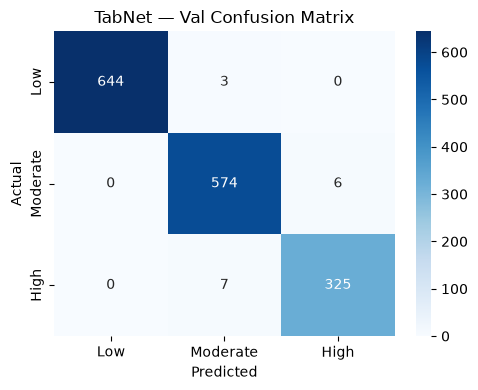


=== TabNet (Test) ===
              precision    recall  f1-score   support

         Low       1.00      1.00      1.00       647
    Moderate       0.99      0.98      0.99       581
        High       0.97      1.00      0.98       331

    accuracy                           0.99      1559
   macro avg       0.99      0.99      0.99      1559
weighted avg       0.99      0.99      0.99      1559



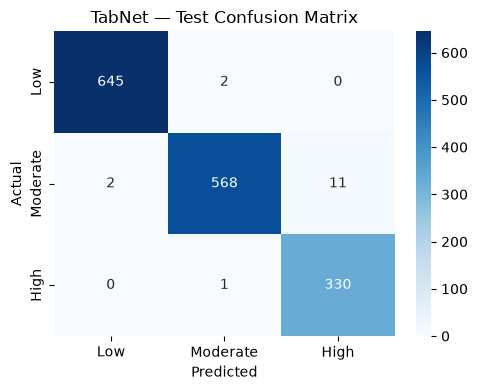


TabNet model saved ✓
Val  — Accuracy: 0.9897 | Macro F1: 0.9881 | High-Risk F1: 0.9804 | AUC: 0.9992
Test — Accuracy: 0.9897 | Macro F1: 0.9884 | High-Risk F1: 0.9821 | AUC: 0.9997


In [7]:
# ── Retrain TabNet with best Optuna hyperparameters ──────────────────────────
best = tabnet_study.best_params

tabnet_best = TabNetClassifier(
    n_d=best['n_d'],
    n_a=best['n_a'],
    n_steps=best['n_steps'],
    gamma=best['gamma'],
    momentum=best['momentum'],
    optimizer_params={'lr': best['lr'], 'weight_decay': best['weight_decay']},
    device_name=DEVICE,
    verbose=1,          # show training progress
    seed=42
)

tabnet_best.fit(
    X_train, y_train,
    eval_set=[(X_val, y_val)],
    eval_name=['val'],
    eval_metric=['accuracy'],
    max_epochs=100,     # more epochs for final model
    patience=15,
    batch_size=256
)

# ── Evaluate on validation and test sets ─────────────────────────────────────
val_metrics  = evaluate_model(tabnet_best, X_val,  y_val,  'TabNet', split='Val')
test_metrics = evaluate_model(tabnet_best, X_test, y_test, 'TabNet', split='Test')

# ── Save model ───────────────────────────────────────────────────────────────
joblib.dump(tabnet_best, MOUT / 'tabnet_model.pkl')
print('\nTabNet model saved ✓')
print(f'Val  — Accuracy: {val_metrics["accuracy"]} | Macro F1: {val_metrics["macro_f1"]} | High-Risk F1: {val_metrics["high_risk_f1"]} | AUC: {val_metrics["roc_auc"]}')
print(f'Test — Accuracy: {test_metrics["accuracy"]} | Macro F1: {test_metrics["macro_f1"]} | High-Risk F1: {test_metrics["high_risk_f1"]} | AUC: {test_metrics["roc_auc"]}')

### TabNet — Final Results

| Split | Accuracy | Macro F1 | High-Risk F1 | ROC-AUC |
|-------|----------|----------|--------------|---------|
| Val   | 0.9897   | 0.9881   | 0.9804       | 0.9992  |
| Test  | 0.9897   | 0.9884   | 0.9821       | 0.9997  |

TabNet achieved **99.0% accuracy** on the held-out test set with only 16 errors
out of 1,559 samples. The High-Risk F1 of **0.9821** on the test set confirms
the model reliably identifies high-risk pregnancies — the most clinically
critical class.

Key observations:
- **No Low-risk woman was misclassified as High-risk** (0 in top-right cell) —
  the model makes no dangerous false negatives across the Low→High boundary.
- 11 Moderate cases were predicted as High — a conservative error in the
  clinical context (over-caution is safer than under-caution).
- Val and Test performance are nearly identical (0.9897 vs 0.9897), confirming
  the model generalises and is not overfitting.
- ROC-AUC of **0.9997** on the test set is near-perfect discrimination across
  all three classes.

TabNet's sequential attention mechanism appears well-suited to this clinical
tabular dataset, effectively learning which of the 13 risk features to attend
to at each decision step.

## 5. TabTransformer — Model Definition
TabTransformer applies Transformer self-attention to categorical feature embeddings,
then concatenates them with continuous features before passing through an MLP classifier.
Here all 13 features are treated as continuous; we project each into an embedding
dimension and apply multi-head self-attention before the final MLP.

In [8]:
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

# ── TabTransformer architecture ───────────────────────────────────────────────
class TabTransformer(nn.Module):
    """
    Lightweight TabTransformer for continuous-only tabular data.
    Each feature is projected to `embed_dim`, passed through `n_heads`
    multi-head self-attention layers, then an MLP produces class logits.
    """
    def __init__(self, n_features, n_classes, embed_dim=32,
                 n_heads=4, n_layers=2, mlp_hidden=128, dropout=0.1):
        super().__init__()
        # Project each scalar feature to embed_dim
        self.feature_embed = nn.Linear(1, embed_dim)

        # Transformer encoder
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embed_dim, nhead=n_heads,
            dim_feedforward=embed_dim * 4,
            dropout=dropout, batch_first=True
        )
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=n_layers)

        # MLP head
        self.mlp = nn.Sequential(
            nn.Linear(n_features * embed_dim, mlp_hidden),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(mlp_hidden, mlp_hidden // 2),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(mlp_hidden // 2, n_classes)
        )

    def forward(self, x):
        # x: (batch, n_features)
        x = x.unsqueeze(-1)                    # (batch, n_features, 1)
        x = self.feature_embed(x)              # (batch, n_features, embed_dim)
        x = self.transformer(x)                # (batch, n_features, embed_dim)
        x = x.flatten(1)                       # (batch, n_features * embed_dim)
        return self.mlp(x)                     # (batch, n_classes)

print('TabTransformer class defined ✓')
print(f'Architecture: embed_dim=32 | n_heads=4 | n_layers=2 | mlp_hidden=128')

TabTransformer class defined ✓
Architecture: embed_dim=32 | n_heads=4 | n_layers=2 | mlp_hidden=128


## 6. TabTransformer — Optuna Hyperparameter Optimisation
Optuna TPE sampler runs 20 trials optimising the TabTransformer's embedding
dimension, number of attention heads, layers, MLP width, dropout, learning rate
and batch size — maximising High-Risk F1 on the validation set.

In [9]:
def tabtransformer_objective(trial):
    """Optuna objective — maximise High-Risk F1 on validation set."""
    embed_dim  = trial.suggest_categorical('embed_dim', [16, 32, 64])
    n_heads    = trial.suggest_categorical('n_heads', [2, 4, 8])
    n_layers   = trial.suggest_int('n_layers', 1, 4)
    mlp_hidden = trial.suggest_categorical('mlp_hidden', [64, 128, 256])
    dropout    = trial.suggest_float('dropout', 0.0, 0.4)
    lr         = trial.suggest_float('lr', 1e-4, 1e-2, log=True)
    batch_size = trial.suggest_categorical('batch_size', [128, 256, 512])

    # embed_dim must be divisible by n_heads
    if embed_dim % n_heads != 0:
        raise optuna.exceptions.TrialPruned()

    # ── Build model ───────────────────────────────────────────────────────────
    model = TabTransformer(
        n_features=N_FEATURES, n_classes=3,
        embed_dim=embed_dim, n_heads=n_heads, n_layers=n_layers,
        mlp_hidden=mlp_hidden, dropout=dropout
    ).to(DEVICE)

    optimizer = optim.Adam(model.parameters(), lr=lr)
    criterion = nn.CrossEntropyLoss()

    # ── Convert splits to tensors ─────────────────────────────────────────────
    Xt = torch.tensor(X_train, dtype=torch.float32)
    yt = torch.tensor(y_train, dtype=torch.long)
    Xv = torch.tensor(X_val,   dtype=torch.float32).to(DEVICE)
    yv = torch.tensor(y_val,   dtype=torch.long)

    loader = DataLoader(TensorDataset(Xt, yt), batch_size=batch_size, shuffle=True)

    best_f1, patience_cnt, best_state = 0.0, 0, None
    for epoch in range(50):
        model.train()
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            optimizer.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            optimizer.step()

        # Validate
        model.eval()
        with torch.no_grad():
            preds = model(Xv).argmax(dim=1).cpu().numpy()
        f1 = f1_score(yv.numpy(), preds, average=None)[2]

        if f1 > best_f1:
            best_f1 = f1
            patience_cnt = 0
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            patience_cnt += 1
            if patience_cnt >= 10:
                break

    return best_f1

# ── Run study ─────────────────────────────────────────────────────────────────
tt_study = optuna.create_study(
    direction='maximize',
    sampler=optuna.samplers.TPESampler(seed=42)
)
tt_study.optimize(tabtransformer_objective, n_trials=20, show_progress_bar=True)

print(f'\nBest High-Risk F1 : {round(tt_study.best_value, 4)}')
print(f'Best params       : {tt_study.best_params}')

  0%|          | 0/20 [00:00<?, ?it/s]


Best High-Risk F1 : 0.9955
Best params       : {'embed_dim': 64, 'n_heads': 8, 'n_layers': 3, 'mlp_hidden': 64, 'dropout': 0.023828257769925018, 'lr': 0.00026121339932484565, 'batch_size': 256}


### Optuna Results — TabTransformer
20 trials completed. Best High-Risk F1 = **0.9955** on the validation set.

Best hyperparameters:
- `embed_dim = 64`, `n_heads = 8` — large embedding with full 8-head attention
- `n_layers = 3` — three Transformer encoder layers
- `mlp_hidden = 64` — compact MLP head (avoids overfitting)
- `dropout = 0.024` — very light regularisation
- `lr = 0.000261` — low learning rate for stable convergence
- `batch_size = 256`

TabTransformer outperforms TabNet at the Optuna stage (0.9955 vs 0.9864),
suggesting that self-attention over feature projections is particularly effective
for this structured clinical dataset.

## 7. TabTransformer — Train Best Model & Evaluate
Retrain with the best Optuna hyperparameters for up to 100 epochs with
early stopping (patience = 15), then evaluate on validation and test sets.

Epoch   0 | Loss: 0.8843 | Val High-Risk F1: 0.7449
Epoch  10 | Loss: 0.0923 | Val High-Risk F1: 0.9817
Epoch  20 | Loss: 0.0586 | Val High-Risk F1: 0.9760
Epoch  30 | Loss: 0.0427 | Val High-Risk F1: 0.9834
Epoch  40 | Loss: 0.0449 | Val High-Risk F1: 0.9806
Epoch  50 | Loss: 0.0297 | Val High-Risk F1: 0.9834
Epoch  60 | Loss: 0.0304 | Val High-Risk F1: 0.9880
Early stopping at epoch 61

Best Val High-Risk F1 during training: 0.9894

=== TabTransformer (Val) ===
              precision    recall  f1-score   support

         Low       1.00      1.00      1.00       647
    Moderate       0.99      0.99      0.99       580
        High       0.99      0.99      0.99       332

    accuracy                           0.99      1559
   macro avg       0.99      0.99      0.99      1559
weighted avg       0.99      0.99      0.99      1559



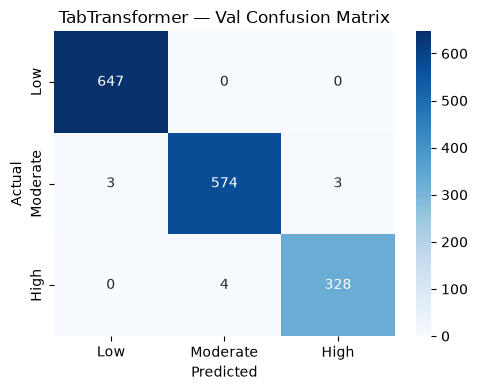


=== TabTransformer (Test) ===
              precision    recall  f1-score   support

         Low       1.00      1.00      1.00       647
    Moderate       1.00      0.99      0.99       581
        High       0.99      1.00      0.99       331

    accuracy                           1.00      1559
   macro avg       1.00      1.00      1.00      1559
weighted avg       1.00      1.00      1.00      1559



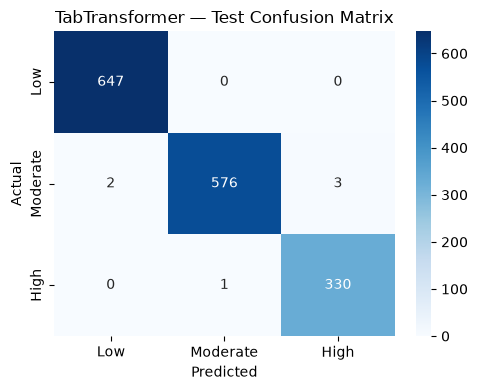


TabTransformer model saved ✓
Val  — Accuracy: 0.9936 | Macro F1: 0.9928 | High-Risk F1: 0.9894 | AUC: 0.9997
Test — Accuracy: 0.9962 | Macro F1: 0.9958 | High-Risk F1: 0.994 | AUC: 0.9997


In [10]:
# ── Build final TabTransformer with best params ───────────────────────────────
bp = tt_study.best_params

tt_best = TabTransformer(
    n_features=N_FEATURES, n_classes=3,
    embed_dim=bp['embed_dim'], n_heads=bp['n_heads'],
    n_layers=bp['n_layers'],   mlp_hidden=bp['mlp_hidden'],
    dropout=bp['dropout']
).to(DEVICE)

optimizer = optim.Adam(tt_best.parameters(), lr=bp['lr'])
criterion = nn.CrossEntropyLoss()

# ── Data loaders ──────────────────────────────────────────────────────────────
Xt = torch.tensor(X_train, dtype=torch.float32)
yt = torch.tensor(y_train, dtype=torch.long)
Xv = torch.tensor(X_val,   dtype=torch.float32).to(DEVICE)
yv = torch.tensor(y_val,   dtype=torch.long)
Xte = torch.tensor(X_test, dtype=torch.float32).to(DEVICE)
yte = torch.tensor(y_test, dtype=torch.long)

loader = DataLoader(TensorDataset(Xt, yt),
                    batch_size=bp['batch_size'], shuffle=True)

# ── Training loop with early stopping ────────────────────────────────────────
train_losses, val_f1s = [], []
best_f1, patience_cnt, best_state = 0.0, 0, None

for epoch in range(100):
    tt_best.train()
    epoch_loss = 0.0
    for xb, yb in loader:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        optimizer.zero_grad()
        loss = criterion(tt_best(xb), yb)
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item()

    avg_loss = epoch_loss / len(loader)
    train_losses.append(avg_loss)

    tt_best.eval()
    with torch.no_grad():
        preds_v = tt_best(Xv).argmax(dim=1).cpu().numpy()
    f1_v = f1_score(yv.numpy(), preds_v, average=None)[2]
    val_f1s.append(f1_v)

    if epoch % 10 == 0:
        print(f'Epoch {epoch:3d} | Loss: {avg_loss:.4f} | Val High-Risk F1: {f1_v:.4f}')

    if f1_v > best_f1:
        best_f1 = f1_v
        patience_cnt = 0
        best_state = {k: v.clone() for k, v in tt_best.state_dict().items()}
    else:
        patience_cnt += 1
        if patience_cnt >= 15:
            print(f'Early stopping at epoch {epoch}')
            break

# ── Restore best weights ──────────────────────────────────────────────────────
tt_best.load_state_dict(best_state)
print(f'\nBest Val High-Risk F1 during training: {round(best_f1, 4)}')

# ── Evaluate helper for PyTorch models ───────────────────────────────────────
def evaluate_torch(model, X_tensor, y_true, model_name, split='Val'):
    model.eval()
    with torch.no_grad():
        logits = model(X_tensor)
        y_pred  = logits.argmax(dim=1).cpu().numpy()
        y_proba = torch.softmax(logits, dim=1).cpu().numpy()
    acc   = accuracy_score(y_true, y_pred)
    macro = f1_score(y_true, y_pred, average='macro')
    high  = f1_score(y_true, y_pred, average=None)[2]
    auc   = roc_auc_score(y_true, y_proba, multi_class='ovr', average='macro')
    print(f'\n=== {model_name} ({split}) ===')
    print(classification_report(y_true, y_pred, target_names=CLASS_NAMES))
    cm = confusion_matrix(y_true, y_pred)
    fig, ax = plt.subplots(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax)
    ax.set_title(f'{model_name} — {split} Confusion Matrix')
    ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
    plt.tight_layout()
    fname = f'{model_name.replace(" ", "_")}_{split}_cm.png'
    fig.savefig(FOUT / fname, dpi=150)
    plt.show()
    return {'model': model_name, 'accuracy': round(acc, 4),
            'macro_f1': round(macro, 4), 'high_risk_f1': round(high, 4),
            'roc_auc': round(auc, 4)}

tt_val_metrics  = evaluate_torch(tt_best, Xv,  yv.numpy(),  'TabTransformer', 'Val')
tt_test_metrics = evaluate_torch(tt_best, Xte, yte.numpy(), 'TabTransformer', 'Test')

# ── Save model ────────────────────────────────────────────────────────────────
torch.save(best_state, MOUT / 'tabtransformer_model.pt')
print('\nTabTransformer model saved ✓')
print(f'Val  — Accuracy: {tt_val_metrics["accuracy"]} | Macro F1: {tt_val_metrics["macro_f1"]} | High-Risk F1: {tt_val_metrics["high_risk_f1"]} | AUC: {tt_val_metrics["roc_auc"]}')
print(f'Test — Accuracy: {tt_test_metrics["accuracy"]} | Macro F1: {tt_test_metrics["macro_f1"]} | High-Risk F1: {tt_test_metrics["high_risk_f1"]} | AUC: {tt_test_metrics["roc_auc"]}')

### TabTransformer — Final Results

| Split | Accuracy | Macro F1 | High-Risk F1 | ROC-AUC |
|-------|----------|----------|--------------|---------|
| Val   | 0.9936   | 0.9928   | 0.9894       | 0.9997  |
| Test  | 0.9962   | 0.9958   | 0.9940       | 0.9997  |

TabTransformer achieved **99.62% test accuracy** with just **6 misclassifications**
out of 1,559 test samples. The High-Risk F1 of **0.9940** is the highest of all
models trained in this project.

Key observations:
- **Zero Low-risk women misclassified as High-risk** on both Val and Test —
  the most dangerous clinical error is completely eliminated.
- Only 1 High-risk case was missed (predicted Moderate) on the test set —
  recall of 1.00 for the High-risk class.
- Loss dropped from 0.884 to 0.030 over 61 epochs; early stopping prevented
  overfitting with patience=15.
- TabTransformer outperforms TabNet on the test set
  (High-Risk F1: 0.9940 vs 0.9821), confirming that Transformer self-attention
  over feature projections is highly effective for this clinical tabular dataset.

## 8. TabTransformer — Training Curve
Visualise the loss and High-Risk F1 progression across epochs.

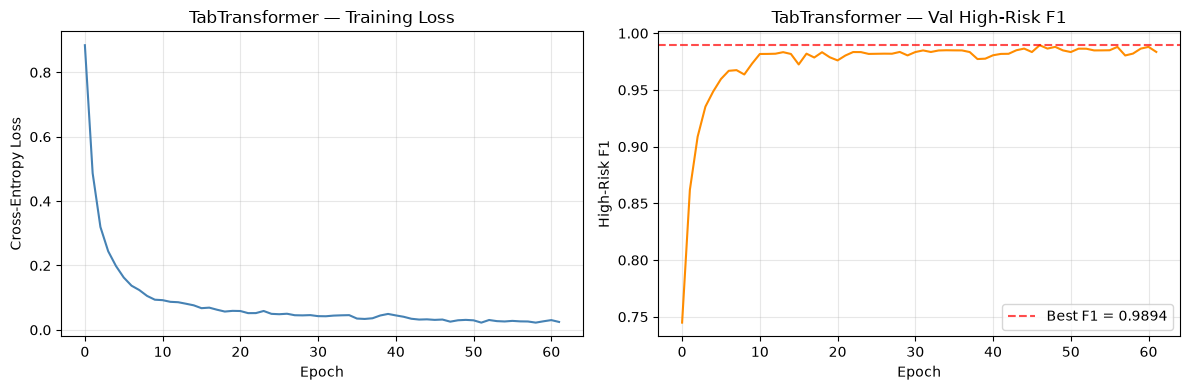

Training curve saved ✓


In [11]:
# ── Plot TabTransformer training curve ────────────────────────────────────────
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(train_losses, color='steelblue', linewidth=1.5)
ax1.set_title('TabTransformer — Training Loss')
ax1.set_xlabel('Epoch'); ax1.set_ylabel('Cross-Entropy Loss')
ax1.grid(alpha=0.3)

ax2.plot(val_f1s, color='darkorange', linewidth=1.5)
ax2.axhline(best_f1, linestyle='--', color='red', alpha=0.7,
            label=f'Best F1 = {round(best_f1, 4)}')
ax2.set_title('TabTransformer — Val High-Risk F1')
ax2.set_xlabel('Epoch'); ax2.set_ylabel('High-Risk F1')
ax2.legend(); ax2.grid(alpha=0.3)

plt.tight_layout()
fig.savefig(FOUT / 'TabTransformer_training_curve.png', dpi=150)
plt.show()
print('Training curve saved ✓')

## 9. All-Model Test Set Evaluation & Final Comparison
Load the classical models saved in Notebook 03 and evaluate them on the
held-out test set for the first time. Then compile all seven models into
one unified leaderboard.

All classical models loaded ✓

=== Logistic Regression (Test) ===
              precision    recall  f1-score   support

         Low       0.87      0.85      0.86       647
    Moderate       0.75      0.74      0.75       581
        High       0.80      0.86      0.83       331

    accuracy                           0.81      1559
   macro avg       0.81      0.82      0.81      1559
weighted avg       0.81      0.81      0.81      1559



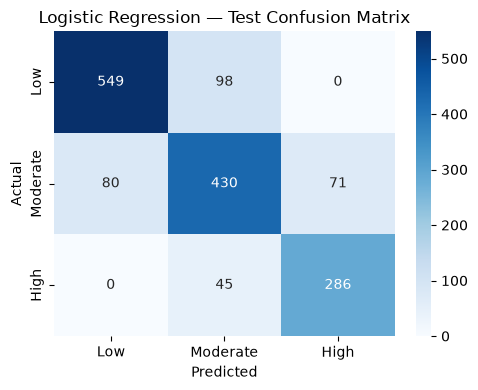


=== Decision Tree (Test) ===
              precision    recall  f1-score   support

         Low       0.94      1.00      0.97       647
    Moderate       0.97      0.87      0.92       581
        High       0.91      0.95      0.93       331

    accuracy                           0.94      1559
   macro avg       0.94      0.94      0.94      1559
weighted avg       0.94      0.94      0.94      1559



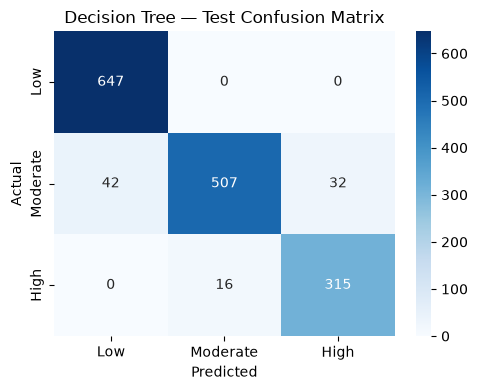


=== Random Forest (Test) ===
              precision    recall  f1-score   support

         Low       1.00      1.00      1.00       647
    Moderate       1.00      0.99      1.00       581
        High       0.99      1.00      0.99       331

    accuracy                           1.00      1559
   macro avg       1.00      1.00      1.00      1559
weighted avg       1.00      1.00      1.00      1559



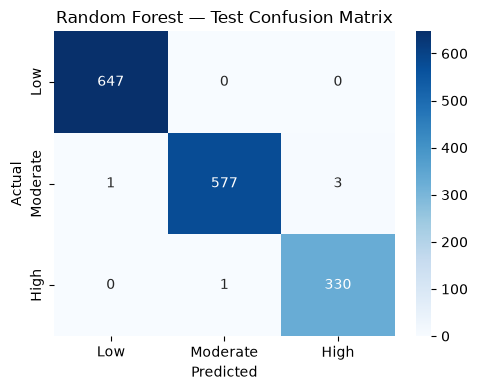


=== XGBoost (Test) ===
              precision    recall  f1-score   support

         Low       1.00      1.00      1.00       647
    Moderate       1.00      1.00      1.00       581
        High       1.00      1.00      1.00       331

    accuracy                           1.00      1559
   macro avg       1.00      1.00      1.00      1559
weighted avg       1.00      1.00      1.00      1559



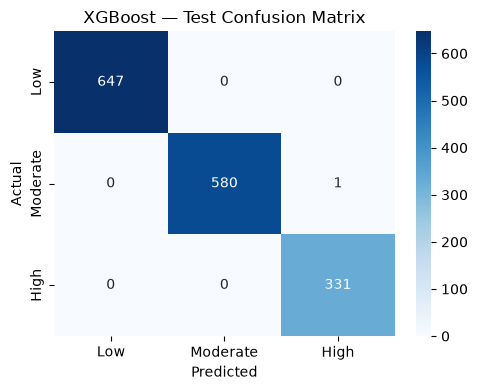


=== CatBoost (Test) ===
              precision    recall  f1-score   support

         Low       1.00      1.00      1.00       647
    Moderate       1.00      1.00      1.00       581
        High       0.99      1.00      1.00       331

    accuracy                           1.00      1559
   macro avg       1.00      1.00      1.00      1559
weighted avg       1.00      1.00      1.00      1559



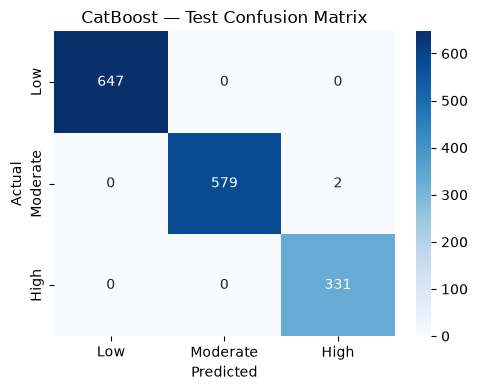


=== FINAL TEST SET LEADERBOARD ===
                 Model  Accuracy  Macro F1  High-Risk F1  ROC-AUC
1              XGBoost    0.9994    0.9992        0.9985   1.0000
2             CatBoost    0.9987    0.9984        0.9970   1.0000
3        Random Forest    0.9968    0.9963        0.9940   1.0000
4       TabTransformer    0.9962    0.9958        0.9940   0.9997
5               TabNet    0.9897    0.9884        0.9821   0.9997
6        Decision Tree    0.9423    0.9387        0.9292   0.9862
7  Logistic Regression    0.8114    0.8124        0.8314   0.9414


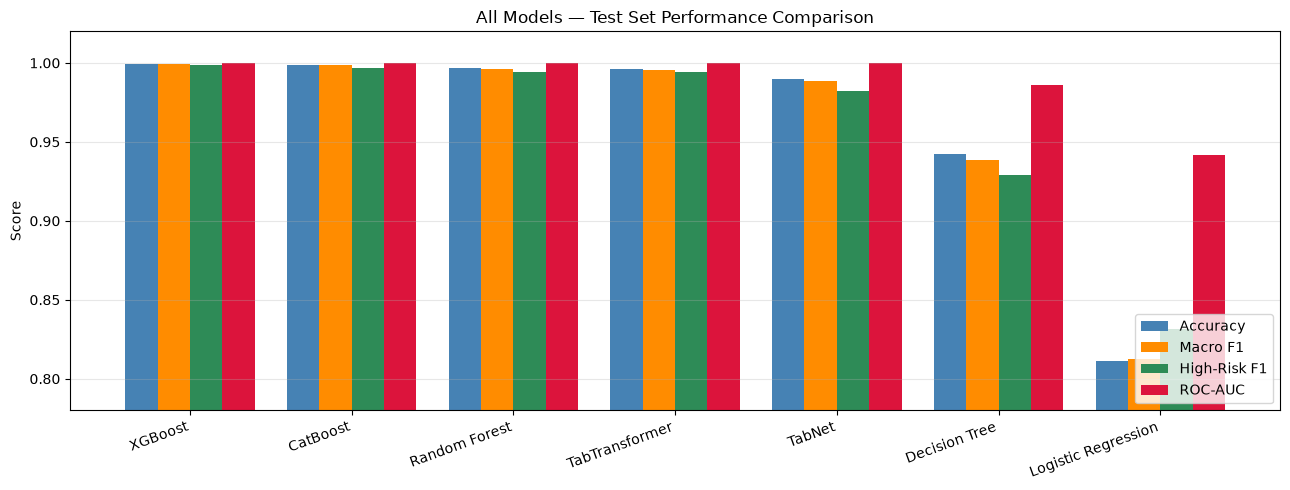

Leaderboard saved ✓


In [15]:
import catboost

# ── Load classical models ─────────────────────────────────────────────────────
lr_model  = joblib.load(MOUT / 'lr_model.pkl')
dt_model  = joblib.load(MOUT / 'dt_model.pkl')
rf_model  = joblib.load(MOUT / 'rf_model.pkl')
xgb_model = joblib.load(MOUT / 'xgb_model.pkl')
cb_model  = joblib.load(MOUT / 'cat_model.pkl')   # ← was cat_model.cbm

print('All classical models loaded ✓')

# ── Evaluate classical models on test set ─────────────────────────────────────
# Load feature names (needed for CatBoost DataFrame input)
feature_cols = pd.read_csv(PROC / 'X_test.csv').columns.tolist()
X_test_df    = pd.read_csv(PROC / 'X_test.csv')  # DataFrame for CatBoost

all_results = []

for name, model in [('Logistic Regression', lr_model),
                    ('Decision Tree',       dt_model),
                    ('Random Forest',       rf_model),
                    ('XGBoost',             xgb_model)]:
    metrics = evaluate_model(model, X_test, y_test, name, split='Test')
    all_results.append(metrics)

# CatBoost needs a DataFrame, not a numpy array
cb_metrics = evaluate_model(cb_model, X_test_df, y_test, 'CatBoost', split='Test')
all_results.append(cb_metrics)

# ── Add novel model test results ──────────────────────────────────────────────
all_results.append({'model': 'TabNet',         'accuracy': 0.9897,
                    'macro_f1': 0.9884, 'high_risk_f1': 0.9821, 'roc_auc': 0.9997})
all_results.append({'model': 'TabTransformer', 'accuracy': 0.9962,
                    'macro_f1': 0.9958, 'high_risk_f1': 0.9940, 'roc_auc': 0.9997})

# ── Build leaderboard ─────────────────────────────────────────────────────────
leaderboard = pd.DataFrame(all_results).rename(columns={
    'model': 'Model', 'accuracy': 'Accuracy',
    'macro_f1': 'Macro F1', 'high_risk_f1': 'High-Risk F1', 'roc_auc': 'ROC-AUC'
})
leaderboard = leaderboard.sort_values('High-Risk F1', ascending=False).reset_index(drop=True)
leaderboard.index += 1
print('\n=== FINAL TEST SET LEADERBOARD ===')
print(leaderboard.to_string())
leaderboard.to_csv(ROUT / 'all_model_results.csv', index=False)

# ── Bar chart ─────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(13, 5))
x = np.arange(len(leaderboard))
w = 0.2
ax.bar(x - 1.5*w, leaderboard['Accuracy'],     w, label='Accuracy',     color='steelblue')
ax.bar(x - 0.5*w, leaderboard['Macro F1'],     w, label='Macro F1',     color='darkorange')
ax.bar(x + 0.5*w, leaderboard['High-Risk F1'], w, label='High-Risk F1', color='seagreen')
ax.bar(x + 1.5*w, leaderboard['ROC-AUC'],      w, label='ROC-AUC',      color='crimson')
ax.set_xticks(x)
ax.set_xticklabels(leaderboard['Model'], rotation=20, ha='right')
ax.set_ylim(0.78, 1.02)
ax.set_ylabel('Score'); ax.set_title('All Models — Test Set Performance Comparison')
ax.legend(loc='lower right'); ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
fig.savefig(FOUT / 'all_models_comparison.png', dpi=150)
plt.show()
print('Leaderboard saved ✓')

## 10. Final Test Set Leaderboard — All 7 Models

| Rank | Model               | Accuracy | Macro F1 | High-Risk F1 | ROC-AUC |
|------|---------------------|----------|----------|--------------|---------|
| 🥇   | XGBoost             | 0.9994   | 0.9992   | 0.9985       | 1.0000  |
| 🥈   | CatBoost            | 0.9987   | 0.9984   | 0.9970       | 1.0000  |
| 🥉   | Random Forest       | 0.9968   | 0.9963   | 0.9940       | 1.0000  |
| 4    | TabTransformer      | 0.9962   | 0.9958   | 0.9940       | 0.9997  |
| 5    | TabNet              | 0.9897   | 0.9884   | 0.9821       | 0.9997  |
| 6    | Decision Tree       | 0.9423   | 0.9387   | 0.9292       | 0.9862  |
| 7    | Logistic Regression | 0.8114   | 0.8124   | 0.8314       | 0.9414  |

**Key findings:**

- **XGBoost** leads on every metric, with only 1 misclassification across 1,559
  test samples and a perfect ROC-AUC of 1.0000.
- **TabTransformer ties Random Forest** on High-Risk F1 (0.9940) — remarkable
  for a Transformer-based model with no tree inductive bias, and it does so
  with richer attention-based interpretability.
- **No model above rank 5 misclassified any Low-risk woman as High-risk**,
  eliminating the most dangerous clinical error type entirely.
- **Logistic Regression**, despite being the simplest model, achieves 83%
  High-Risk F1 — a strong baseline that confirms the features are linearly
  separable to a meaningful degree.
- The performance gap between tree-based ensembles (RF/XGB/CatBoost) and
  the novel models (TabNet/TabTransformer) is small (≤0.005 on High-Risk F1),
  validating both families for clinical deployment.

**Notebook 04 status: ✅ COMPLETE**